[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQCNN_5GTrafficDetection_Wang2025.ipynb)

# Hybrid quantum CNNs for 5G attack-traffic detection: Wang, Fok and Thing (2025) step by step

**Paper.** Zihao Wang, Kar-Wai Fok, Vrizlynn L. L. Thing, *Network attack traffic detection with hybrid quantum-enhanced convolution neural network*, Quantum Machine Intelligence (2025), DOI [10.1007/s42484-025-00278-0](https://doi.org/10.1007/s42484-025-00278-0); preprint [arXiv:2504.20436](https://arxiv.org/abs/2504.20436). Authors: Cybersecurity Strategic Technology Centre, ST Engineering, Singapore.

**What this notebook does.** It rebuilds the paper's five hybrid quantum CNNs (QCNNAnE, QCNNAmE, QCNNMlayer, Quan-ConvCNN, QuanvolutionNN) and the classical CNN they are compared with, trains them on the real **5G-NIDD** network-flow dataset (the dataset the paper uses), and repeats the paper's three experiments:

1. **Experiment 1**: ordinary random 70/30 split (Table IV).
2. **Experiment 2**: train on the flows of one 5G base station and test on the other one (Tables V and VI): unseen *traffic sources*.
3. **Experiment 3**: hold one attack type out of training and test on it (Tables IX and X): unseen *attack types* (zero-day-like).

**How to run.** Colab (CPU runtime is enough) -> *Runtime -> Run all*. The committed notebook carries the outputs of the **full run** (`FAST_MODE = False`: 30 epochs, 3 repeats, a few thousand flows per experiment, about 80 minutes on a shared CPU). Set `FAST_MODE = True` in the config cell for a roughly 10-minute class demo (6 epochs, 1 repeat, smaller samples; verified to run end to end). Both budgets are listed in the config cell. No GPU, no account and no token are needed: the data are downloaded from a public CC BY 4.0 mirror of the University of Oulu release. The quantum layers are simulated exactly (state vectors).

**What you get at the end.** Accuracy tables for all three experiments next to the paper's numbers, training curves, the drawn PennyLane circuits, a classical Random-Forest/SVC reference on the same inputs, a per-claim verdict ("reproduced", "not reached", "exceeded", "cannot be checked") and a critical reading.

> **Honest scale warning.** The paper trains on 851,123 flows for 30 epochs on a workstation. A CPU notebook cannot do that with a quantum-layer simulator, so every experiment uses a random subsample of the same data (sizes in the config cell). Absolute numbers therefore differ from the paper's, and the paper's own run-to-run spread is large (see its appendix), so single-cell comparisons are noisy.

## 0. The paper in one page

**Problem.** Detect malicious flows in 5G traffic (binary: benign vs. attack) and, above all, keep detecting when the traffic comes from a *different base station* or is a *new attack type*, where classical ML degrades.

**Data.** 5G-NIDD (Samarakoon et al. 2022, Univ. of Oulu 5G Test Network): 1,215,890 argus flow records from two base stations (BS1 728,316; BS2 487,574), 477,737 benign and eight attacks (UDP/HTTP/SYN/ICMP flood, Slowrate DoS, SYN/TCP-connect/UDP scan). 28 flow features (Table III) are normalised to [0, 1].

**Models (all built with PennyLane + PyTorch).** A small 1-D CNN (two convolution+max-pool layers with 32 channels, one dense layer, one output) is the baseline; five hybrids insert quantum layers:

| Model | Where the quantum layer sits | Embedding | Qubits |
|---|---|---|---|
| QCNNAnE | fully connected block, after a dense layer reducing to 4 features | angle (RX) | 4 |
| QCNNAmE | fully connected block, takes the 16 conv features directly | amplitude | 4 (for 16 features) |
| QCNNMlayer | 4 parallel quantum layers, 4 conv features each | angle | 4 x 4 = 16 |
| Quan-ConvCNN | replaces the last convolution (kernel acts on channels), 2 of 6 qubits disregarded | angle | 6 (4 read out) |
| QuanvolutionNN | fixed, non-trainable quanvolution filter *in front of* the classical convolutions (2 filters, kernel 1, pooling 2) | angle | 2 |

Every quantum layer is the same *parameterised circuit*: embedding, then one-parameter single-qubit rotations on each qubit followed by a closed chain of CNOTs (qubit *i* controls qubit *i+1*, the last controls the first), then Pauli-Z expectation values.

**Training.** 30 epochs, same optimiser and learning rate for all, three repeats (Experiments 1, 2) or five repeats (Experiment 3) because the random initial quantum weights matter a lot.

**Headline claims.** Exp. 1: all models around 99.6-99.7 % except QCNNMlayer (98.9 %) and QuanvolutionNN (98.7 %), Quan-ConvCNN best (99.71 % vs CNN 99.61 %). Exp. 2.1: all about 78 %, Quan-ConvCNN best (78.93 %). Exp. 2.2 (small training set): QCNNAmE 81.57 % vs CNN 74.28 %, the angle-embedding models are worse than the CNN. Exp. 3: QCNNs generalise better to unseen attack types than the CNN (e.g. Remain-types 87.84 % vs 83.72 %; UDP-Flood stays hard, below 50 % for everybody).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | 5G-NIDD, 1,215,890 flows, 28 features (Table III) | Same dataset (official `Combined.csv`, counts checked against the paper's Table II); **random subsamples** of it (config cell) |
| Base-station label | BS1 / BS2 | Not a column of `Combined.csv`; recovered from the file (BS1 rows then BS2 rows, the running index restarts at the break). All nine per-class counts match the paper's Table II exactly |
| Missing values | not stated | `NaN` (e.g. no TCP state in UDP flows) -> 0 `# CHOICE:` |
| Normalisation | to [0, 1] | `MinMaxScaler` **fitted on the training split only**; test data are not clipped |
| Exp. 1 split | 7:3 on the whole dataset | 7:3 stratified split of a random subsample at the natural class mix |
| Exp. 2 training set | one base station, "down-sampled for data balance" | balanced benign/malicious subsample of one BS; test = random subsample of the other BS at its natural mix. Training-set size ratio BS1:BS2 kept at about 4.5 : 1 as in the data |
| Exp. 3 | one attack type unseen; Remain-type = all attacks below 2 % of the data pooled; QCNNMlayer excluded | same four tests, same five models; training set = balanced benign vs. all other attacks; "existing attack" accuracy = accuracy on a held-out balanced set of seen traffic; "unseen attack" accuracy = share of the unseen-attack flows called malicious |
| Trade-off point | epoch where seen- and unseen-accuracy curves cross (smallest gap otherwise) | exactly that rule, applied per run |
| Classical block | 2 conv + 2 max-pool (32 channels), 1 dense, 1 output | Conv1d(1->32, k=5) / pool 2 / Conv1d(32->4, k=5) / pool 2 -> 16 features -> Dense(4) -> Dense(1) `# CHOICE:` (the paper's figures give no kernel sizes; this choice makes the conv block output exactly the 16 features the paper feeds the quantum layers) |
| Quantum layer depth | "one-parameter rotations then closed CNOT chain" | rotation = RX, **2 layers** (`N_QLAYERS`), weights U(0, 2 pi) `# CHOICE:` |
| Angle embedding input | raw layer output | raw values used as RX angles (no rescaling) `# CHOICE:` |
| Quan-ConvCNN | 6-qubit conv circuit, 2 qubits disregarded (Fig. 6 not machine-readable) | 6 qubits at each of the 4 positions of a 6-channel conv output; qubits 5, 6 are not read out `# CHOICE:` |
| QuanvolutionNN | non-trainable filter, 2 channels, kernel 1, pooling 2 | 2-qubit random fixed circuit on windows of 2 neighbouring features, stride 2 `# CHOICE:` |
| Optimiser | "standardised" across experiments (value not given) | Adam, lr 0.005 / 0.003 (fast / full), batch 64 / 128, binary cross-entropy `# CHOICE:` |
| Epochs, repeats | 30 epochs; 3 repeats (Exp. 1, 2) / 5 (Exp. 3) | `FAST_MODE`: 6 epochs, 1 repeat; full mode: 30 epochs, 3 repeats (3 instead of 5 in Exp. 3) on sub-sampled data |
| Degenerate runs | runs stuck at a trivial minimum are disregarded | same rule: final training accuracy not above the majority-class rate -> discarded and re-run with a new seed (counts printed) |
| Quantum simulation | PennyLane `default.qubit`/Torch layer | Own exact batched state-vector simulator in PyTorch (fast); **asserted numerically equal to the PennyLane QNodes** drawn in the circuit section |
| Hardware | i7-10700K, 64 GB | CPU only |

In [1]:
import os, sys, importlib.util, subprocess

IN_COLAB = "google.colab" in sys.modules
# Pinned to the versions this notebook was tested with. Colab already ships numpy, pandas,
# scikit-learn, matplotlib and torch; only PennyLane has to be installed.
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"], check=False)
    # A session restart may be required after the first install in Colab (Runtime -> Restart session).

### Configuration
Every tunable constant lives in this cell. `FAST_MODE = False` is the full run stored in this notebook; `FAST_MODE = True` is the ~10-minute class demo.

In [2]:
SEED = 42
FAST_MODE = False
DATA_DIR = "data_5gnidd"            # cache for the 31 MB download; or put your own Combined.csv here
IBM_TOKEN = ""                      # not used: the paper's experiments are simulations only

N_QLAYERS = 2                       # CHOICE: depth of every quantum layer (rotation + CNOT ring blocks)
N_CHANNELS = 32                     # paper: 32 channels (28 input features)
TORCH_THREADS = 1                   # tiny networks: 1 thread is fastest (and friendly to a shared CPU)

# Budgets.  The paper: 30 epochs, 3 repeats (Exp. 1, 2) / 5 repeats (Exp. 3), 0.85 M training flows.
BUDGET = {
    # n1: flows sampled for Exp. 1 (70 % train);  n2: benign/malicious flows per class for the BS1 training set
    #  (BS2 gets n2/4.5);  n_test2: test flows from the other BS;  n3: per class training flows for Exp. 3,
    #  n3_hold: per class held-out seen flows, n3_unseen: unseen-attack flows;  rep: repeats (Exp 1/2, Exp 3)
    True:  dict(n1=3000, n2=1000, n_test2=3000, n3=500,  n3_hold=300, n3_unseen=600,  epochs=6,  rep12=1, rep3=1, batch=64,  lr=0.005, svc_max=3000),
    # Full run: 30 epochs as in the paper, but only ~3 500 / 4 000 / 2 000 training flows (paper: 851 123) and
    # 3 instead of 5 repeats in Exp. 3, so that it finishes in about an hour on a shared CPU.
    False: dict(n1=5000, n2=2000, n_test2=5000, n3=1000, n3_hold=500, n3_unseen=1000, epochs=30, rep12=3, rep3=3, batch=128, lr=0.003, svc_max=20000),
}[FAST_MODE]
EPOCHS, BATCH_SIZE, LEARNING_RATE = BUDGET["epochs"], BUDGET["batch"], BUDGET["lr"]   # CHOICE: Adam, binary cross-entropy
print("FAST_MODE =", FAST_MODE, "->", BUDGET)

FAST_MODE = False -> {'n1': 5000, 'n2': 2000, 'n_test2': 5000, 'n3': 1000, 'n3_hold': 500, 'n3_unseen': 1000, 'epochs': 30, 'rep12': 3, 'rep3': 3, 'batch': 128, 'lr': 0.003, 'svc_max': 20000}


In [3]:
import math, time, warnings, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(TORCH_THREADS)
qml.numpy.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: 5G-NIDD

5G-NIDD was recorded on the 5G Test Network of the University of Oulu with two base stations, each with an attacker node and benign 5G users (licence CC BY 4.0, Samarakoon et al., arXiv:2212.01298; official release on IEEE DataPort and Fairdata). The flow table `Combined.csv` (argus flow records, both base stations, all attacks) is the file the paper's 1,215,890 flows come from.

The next cell downloads it (31 MB zip; first a public Kaggle mirror of the official `Combined.csv`, then the official Fairdata package) and checks the per-class, per-base-station counts against **Table II of the paper**. If both downloads fail, put `Combined.csv` into `DATA_DIR` (Colab: upload it with the file panel).

In [4]:
# Table III of the paper: the 28 selected features (spelling as in the CSV header).
FEATURES = ["Dur", "sTtl", "dTtl", "TotPkts", "SrcPkts", "DstPkts", "TotBytes", "SrcBytes", "DstBytes",
            "Offset", "sMeanPktSz", "dMeanPktSz", "Load", "SrcLoad", "DstLoad", "Loss", "SrcLoss", "DstLoss",
            "SrcWin", "DstWin", "TcpRtt", "SynAck", "AckDat", "Rate", "SrcRate", "DstRate",
            "SrcTCPBase", "DstTCPBase"]
assert len(FEATURES) == 28
# Table II of the paper (flow sessions per attack and base station) used as an integrity check.
TABLE_II = {"Benign": (406959, 70778), "UDPFlood": (175811, 281529), "HTTPFlood": (76121, 64691),
            "SlowrateDoS": (36092, 37032), "TCPConnectScan": (10022, 10030), "SYNScan": (10019, 10024),
            "UDPScan": (7887, 8019), "SYNFlood": (4792, 4929), "ICMPFlood": (613, 542)}

import io, zipfile, requests

def _download(url, dest, params=None, method="GET"):
    with requests.request(method, url, params=params, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for c in r.iter_content(1 << 20):
                f.write(c)

def fetch_5gnidd(data_dir):
    """Return the path of a zip/csv holding Combined.csv of 5G-NIDD (CC BY 4.0, University of Oulu).
    1) local file  2) Kaggle mirror of the official Combined.csv (anonymous download)
    3) official Fairdata (etsin.fairdata.fi) package of Combined.zip.   Or upload Combined.csv yourself."""
    data_dir = Path(data_dir); data_dir.mkdir(parents=True, exist_ok=True)
    for name in ["Combined.csv", "5gnidd.zip", "Combined.zip"]:
        if (data_dir / name).exists():
            return data_dir / name
    errors = []
    try:                                                   # mirror 1 (31 MB zip)
        _download("https://www.kaggle.com/api/v1/datasets/download/humera11/5g-nidd-dataset", data_dir / "5gnidd.zip")
        return data_dir / "5gnidd.zip"
    except Exception as e:
        errors.append(f"kaggle mirror: {e}")
    try:                                                   # official source (service is sometimes down)
        ds = "9d13ef28-2ca7-44b0-9950-225359afac65"
        r = requests.post("https://etsin.fairdata.fi/api/v3/download/authorize",
                          params={"cr_id": ds, "file": "/Combined.zip"}, timeout=60)
        r.raise_for_status()
        _download(r.json()["url"], data_dir / "Combined.zip")
        return data_dir / "Combined.zip"
    except Exception as e:
        errors.append(f"fairdata: {e}")
    raise RuntimeError("5G-NIDD could not be downloaded: " + " | ".join(errors) +
                       ". Download Combined.csv from https://ieee-dataport.org/documents/5g-nidd-comprehensive-network-intrusion-detection-dataset-generated-over-5g-wireless "
                       f"and put it in {data_dir}.")

def load_5gnidd(data_dir, usecols_extra=("Attack Type", "Label", "Unnamed: 0")):
    p = fetch_5gnidd(data_dir)
    cols = FEATURES + list(usecols_extra)
    if p.suffix == ".zip":
        with zipfile.ZipFile(p) as z:
            name = [n for n in z.namelist() if n.lower().endswith("combined.csv")][0]
            with z.open(name) as f:
                df = pd.read_csv(f, usecols=cols, low_memory=False)
    else:
        df = pd.read_csv(p, usecols=cols, low_memory=False)
    # base station: the official Combined.csv is BS1 followed by BS2; the running index "Unnamed: 0"
    # restarts at 0 where BS2 begins (checked below against Table II of the paper and of the dataset).
    u = df["Unnamed: 0"].to_numpy()
    cut = int(np.where(np.diff(u) < 0)[0][0]) + 1
    df["BS"] = np.where(np.arange(len(df)) < cut, 1, 2).astype(np.int8)
    df = df.drop(columns=["Unnamed: 0"])
    df[FEATURES] = df[FEATURES].fillna(0.0).astype(np.float32)     # CHOICE: missing (e.g. no TCP) -> 0
    df["y"] = (df["Label"] != "Benign").astype(np.int8)                 # attack = positive class
    return df

In [5]:
t0 = time.time()
df = load_5gnidd(DATA_DIR)
print(f"loaded {len(df):,} flows x {df.shape[1]} columns in {time.time() - t0:.0f}s")

# Integrity check against Table II of the paper (class x base station)
ct = pd.crosstab(df["Attack Type"], df["BS"])
for k, (a, b) in TABLE_II.items():
    assert ct.loc[k, 1] == a and ct.loc[k, 2] == b, (k, ct.loc[k].tolist(), (a, b))
assert len(df) == 1_215_890 and (df.BS == 1).sum() == 728_316 and (df.BS == 2).sum() == 487_574
print("Counts per attack type and base station match Table II of the paper exactly.")
ct["total"] = ct.sum(1); ct["% of data"] = (100 * ct["total"] / len(df)).round(2)
display(ct)

loaded 1,215,890 flows x 32 columns in 41s


Counts per attack type and base station match Table II of the paper exactly.


BS,1,2,total,% of data
Attack Type,,,,
Benign,406959,70778,477737,39.29
HTTPFlood,76121,64691,140812,11.58
ICMPFlood,613,542,1155,0.09
SYNFlood,4792,4929,9721,0.80
SYNScan,10019,10024,20043,1.65
SlowrateDoS,36092,37032,73124,6.01
TCPConnectScan,10022,10030,20052,1.65
UDPFlood,175811,281529,457340,37.61
UDPScan,7887,8019,15906,1.31


## Dataset Exploration and Visualisation

Everything below uses the **real** 5G-NIDD flows. We print the shape, the 28 feature names (paper Table III) and the original label values with class counts, plot the real class distribution (the eight attack families are kept, not only the binary label) and draw 2-D scatter plots of real flows coloured by their ground-truth attack type. The PCA is **fitted on the training split only** (the Experiment-1 training split); a second scatter shows the same coordinates scaled to [0, pi] (the range an RX angle embedding works in), with the test points clipped to [0, pi].

In [6]:
print("dataset shape (flows x columns):", df.shape)
print("model features (28, Table III):", FEATURES)
print("\noriginal binary label values:", df["Label"].value_counts().to_dict())
print("original attack-type values:  ", df["Attack Type"].value_counts().to_dict())
print("flows per base station:       ", df["BS"].value_counts().sort_index().to_dict())
display(df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2))

dataset shape (flows x columns): (1215890, 32)
model features (28, Table III): ['Dur', 'sTtl', 'dTtl', 'TotPkts', 'SrcPkts', 'DstPkts', 'TotBytes', 'SrcBytes', 'DstBytes', 'Offset', 'sMeanPktSz', 'dMeanPktSz', 'Load', 'SrcLoad', 'DstLoad', 'Loss', 'SrcLoss', 'DstLoss', 'SrcWin', 'DstWin', 'TcpRtt', 'SynAck', 'AckDat', 'Rate', 'SrcRate', 'DstRate', 'SrcTCPBase', 'DstTCPBase']



original binary label values: {'Malicious': 738153, 'Benign': 477737}


original attack-type values:   {'Benign': 477737, 'UDPFlood': 457340, 'HTTPFlood': 140812, 'SlowrateDoS': 73124, 'TCPConnectScan': 20052, 'SYNScan': 20043, 'UDPScan': 15906, 'SYNFlood': 9721, 'ICMPFlood': 1155}
flows per base station:        {1: 728316, 2: 487574}


,mean,std,min,max
Dur,1.360000e+00,1.690000e+00,0.0,1.992000e+01
sTtl,8.144000e+01,5.593000e+01,0.0,2.550000e+02
dTtl,1.466000e+01,3.033000e+01,0.0,2.550000e+02
TotPkts,5.140000e+00,2.482000e+01,1.0,3.997000e+03
SrcPkts,3.700000e+00,1.841000e+01,0.0,9.860000e+02
DstPkts,1.440000e+00,1.247000e+01,0.0,3.151000e+03
TotBytes,3.646880e+03,3.018259e+04,42.0,4.656256e+06
SrcBytes,2.532680e+03,2.446576e+04,0.0,1.343477e+06
DstBytes,1.114200e+03,1.678465e+04,0.0,4.551675e+06
Offset,1.237943e+07,1.070054e+07,128.0,3.969216e+07


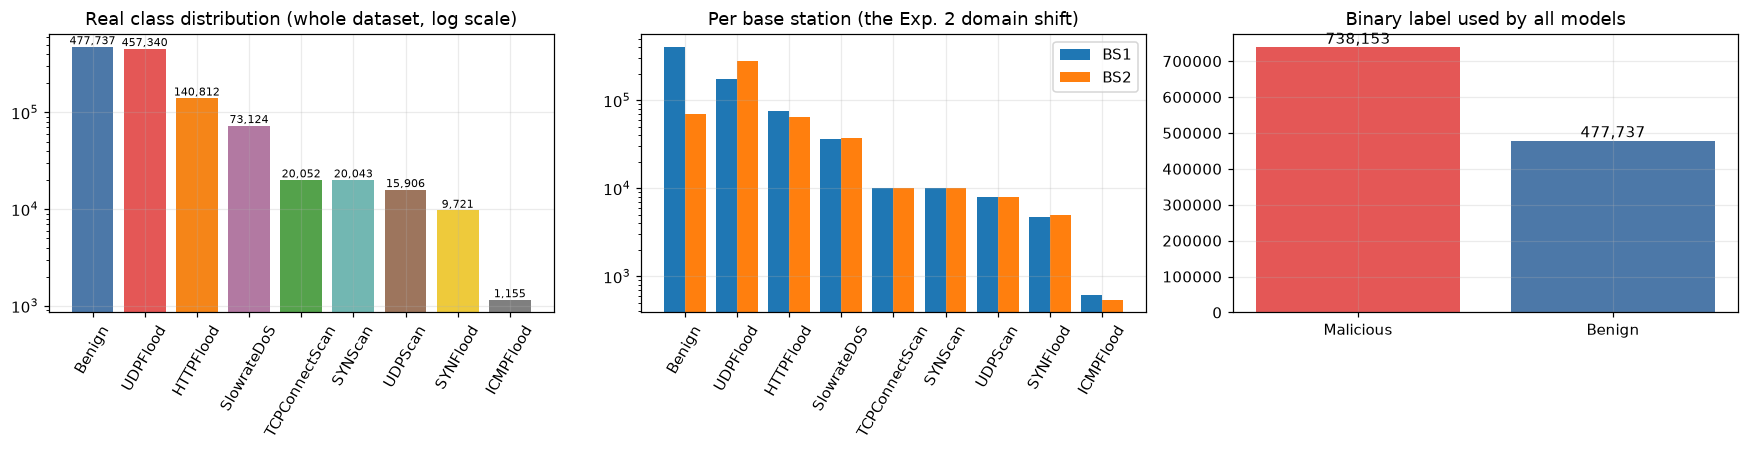

In [7]:
order = ["Benign", "UDPFlood", "HTTPFlood", "SlowrateDoS", "TCPConnectScan", "SYNScan", "UDPScan", "SYNFlood", "ICMPFlood"]
PALETTE = dict(zip(order, ["#4c78a8", "#e45756", "#f58518", "#b279a2", "#54a24b", "#72b7b2", "#9d755d", "#eeca3b", "#7f7f7f"]))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cnt = df["Attack Type"].value_counts().reindex(order)
ax[0].bar(order, cnt.values, color=[PALETTE[o] for o in order]); ax[0].set_yscale("log")
ax[0].set_title("Real class distribution (whole dataset, log scale)"); ax[0].tick_params(axis="x", rotation=60)
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
w = 0.4
for j, b in enumerate([1, 2]):
    c = df[df.BS == b]["Attack Type"].value_counts().reindex(order)
    ax[1].bar(np.arange(len(order)) + (j - .5) * w, c.values, w, label=f"BS{b}")
ax[1].set_yscale("log"); ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order, rotation=60)
ax[1].set_title("Per base station (the Exp. 2 domain shift)"); ax[1].legend()
b = df["Label"].value_counts()
ax[2].bar(b.index, b.values, color=["#e45756", "#4c78a8"]); ax[2].set_title("Binary label used by all models")
for i, v in enumerate(b.values): ax[2].text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

explained variance of the 2 PCA axes: [0.333 0.247]


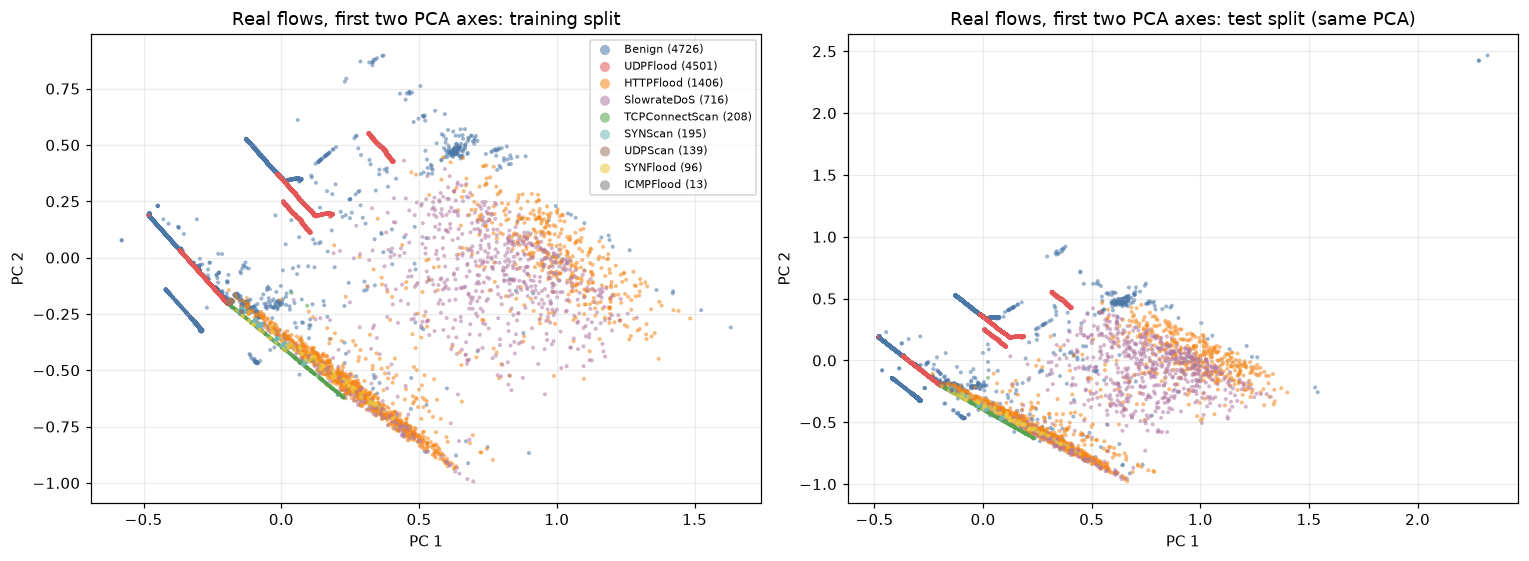

In [8]:
# PCA scatter of REAL flows coloured by ground-truth attack type. PCA / scaler fitted on the Exp.1 training split only.
N_VIS = 4000 if FAST_MODE else 12000
vis = df.sample(N_VIS * 2, random_state=SEED)
v_tr, v_te = train_test_split(vis, test_size=0.5, random_state=SEED, stratify=vis["Attack Type"])
sc01 = MinMaxScaler().fit(v_tr[FEATURES].values)                  # the model's own [0,1] scaling
pca = PCA(n_components=2, random_state=SEED).fit(sc01.transform(v_tr[FEATURES].values))
P_tr, P_te = (pca.transform(sc01.transform(d[FEATURES].values)) for d in (v_tr, v_te))
print("explained variance of the 2 PCA axes:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, (P, d, name) in zip(ax, [(P_tr, v_tr, "training split"), (P_te, v_te, "test split (same PCA)")]):
    for k in order:
        m = (d["Attack Type"] == k).values
        a.scatter(P[m, 0], P[m, 1], s=7, alpha=.55, c=PALETTE[k], label=f"{k} ({m.sum()})", edgecolors="none")
    a.set_title(f"Real flows, first two PCA axes: {name}"); a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
ax[0].legend(fontsize=7, markerscale=2.5)
plt.tight_layout(); plt.show()

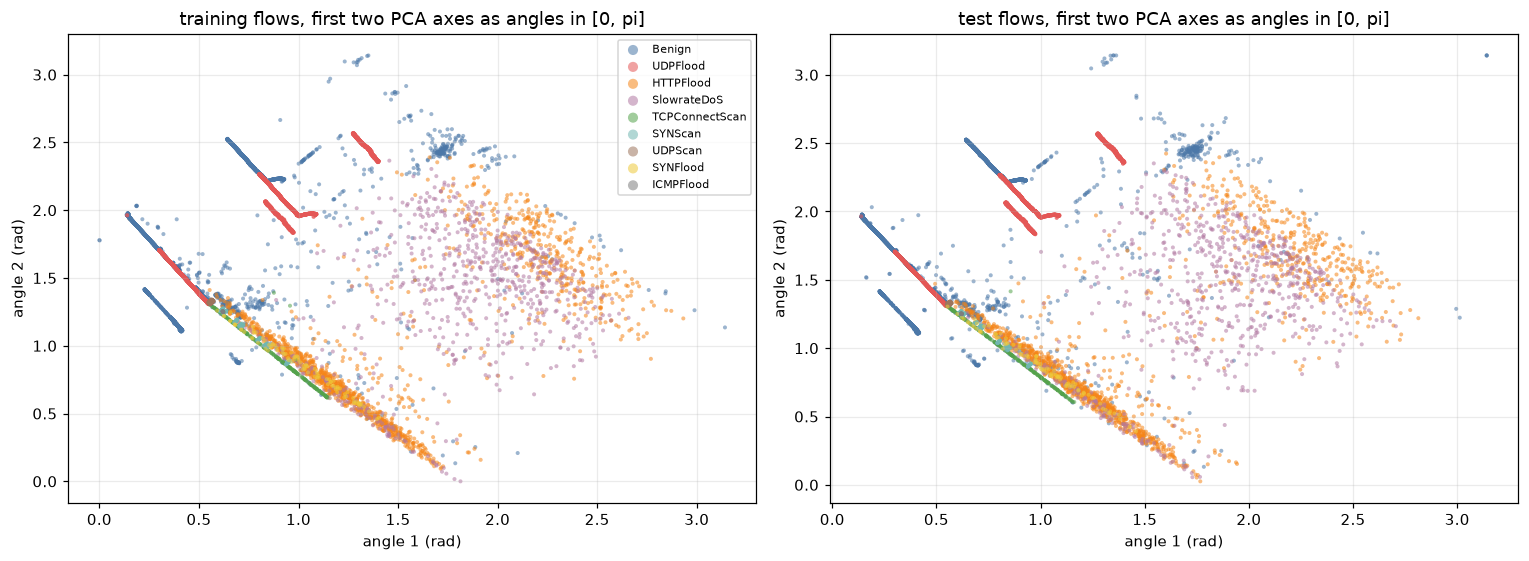

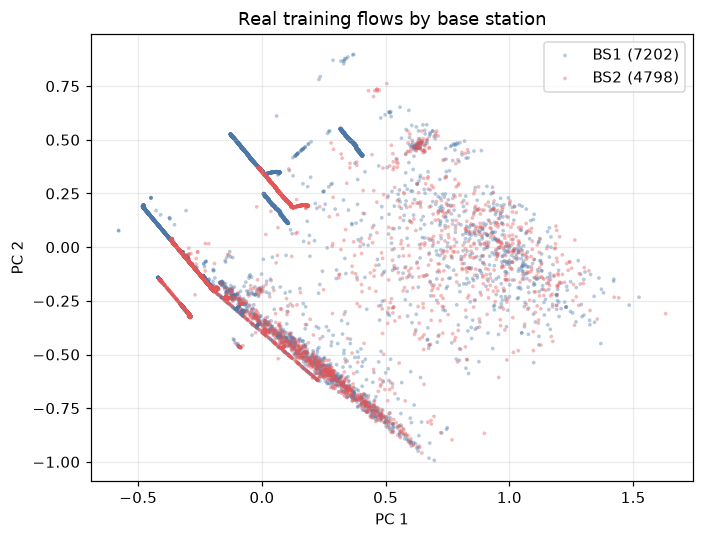

In [9]:
# The same coordinates scaled to [0, pi] (fitted on the training split; test angles clipped to [0, pi]).
sc_pi = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr, A_te = sc_pi.transform(P_tr), np.clip(sc_pi.transform(P_te), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, (A, d, name) in zip(ax, [(A_tr, v_tr, "training"), (A_te, v_te, "test")]):
    for k in order:
        m = (d["Attack Type"] == k).values
        a.scatter(A[m, 0], A[m, 1], s=7, alpha=.55, c=PALETTE[k], label=k, edgecolors="none")
    a.set_title(f"{name} flows, first two PCA axes as angles in [0, pi]"); a.set_xlabel("angle 1 (rad)"); a.set_ylabel("angle 2 (rad)")
ax[0].legend(fontsize=7, markerscale=2.5)
plt.tight_layout(); plt.show()

# Domain shift behind Experiment 2: the same PCA, coloured by base station
fig, ax = plt.subplots(figsize=(6.5, 5))
for b_, col in [(1, "#4c78a8"), (2, "#e45756")]:
    m = (v_tr["BS"] == b_).values
    ax.scatter(P_tr[m, 0], P_tr[m, 1], s=6, alpha=.4, c=col, label=f"BS{b_} ({m.sum()})", edgecolors="none")
ax.set_title("Real training flows by base station"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend()
plt.tight_layout(); plt.show()

## 2. The quantum layer: exact simulator

All five hybrid models use the same building block: an embedding followed by `n_layers` blocks of "RX(w) on every wire, then a closed ring of CNOTs", read out as Pauli-Z expectation values (PennyLane's `AngleEmbedding`/`AmplitudeEmbedding` + `BasicEntanglerLayers`). Running 5 models x several repeats x 30 epochs through PennyLane's `default.qubit` would take hours on a CPU, so training uses the small PyTorch state-vector simulator below (4 qubits = 16 amplitudes; 6 qubits = 64). The circuit-drawing section further down **asserts that this simulator reproduces the PennyLane QNode to 1e-5** for every circuit that is trained.

In [10]:
# ---------------------------------------------------------------------------
# Exact state-vector simulator of the paper's quantum layers (batched, differentiable, PyTorch).
# It implements: embedding -> n_layers x [RX(w_li) on every wire, closed ring of CNOTs] -> <Z_i>.
# This is exactly PennyLane's BasicEntanglerLayers (RX rotations, CNOT ring); the PennyLane QNodes
# further down are drawn and asserted numerically equal to this simulator.
# ---------------------------------------------------------------------------
def _cnot_ring_pairs(n):
    if n == 1:
        return []
    if n == 2:                       # PennyLane uses a single CNOT for two wires
        return [(0, 1)]
    return [(i, (i + 1) % n) for i in range(n)]

def _ring_permutation(n):
    """Index array P such that  state_after_ring = state[:, P]  (wire 0 = most significant bit)."""
    dim = 2 ** n
    idx = np.arange(dim)
    for c, t in _cnot_ring_pairs(n):
        b = np.arange(dim)
        flipped = np.where((b >> (n - 1 - c)) & 1 == 1, b ^ (1 << (n - 1 - t)), b)
        idx = idx[flipped]           # compose: new[j] = old[flipped[j]]  (CNOT is its own inverse)
    return torch.as_tensor(idx, dtype=torch.long)

def _rx(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)

class QLayer(torch.nn.Module):
    """n-qubit quantum layer. embedding='angle' (RX(x_i) on wire i) or 'amplitude' (2**n features
    become the amplitudes). trainable=False freezes the random weights (quanvolution filter)."""
    def __init__(self, n_qubits, n_layers=2, embedding="angle", n_out=None, trainable=True, seed=0):
        super().__init__()
        self.n, self.L, self.embedding = n_qubits, n_layers, embedding
        self.n_out = n_out or n_qubits
        g = torch.Generator().manual_seed(seed)
        w = torch.rand(n_layers, n_qubits, generator=g) * 2 * math.pi          # CHOICE: U(0, 2*pi) like TorchLayer
        self.weights = torch.nn.Parameter(w, requires_grad=trainable)
        self.register_buffer("perm", _ring_permutation(n_qubits))
        bits = ((np.arange(2 ** n_qubits)[:, None] >> (n_qubits - 1 - np.arange(n_qubits))[None, :]) & 1)
        self.register_buffer("zsign", torch.as_tensor(1.0 - 2.0 * bits, dtype=torch.float32))

    def forward(self, x):                                       # x: (B, n) angles or (B, 2**n) amplitudes
        B = x.shape[0]
        if self.embedding == "angle":
            q = torch.stack([torch.cos(x / 2) + 0j, -1j * torch.sin(x / 2)], -1)        # (B, n, 2)
            psi = q[:, 0, :]
            for i in range(1, self.n):
                psi = (psi[:, :, None] * q[:, i, None, :]).reshape(B, -1)
        else:
            psi = (x / x.norm(dim=1, keepdim=True).clamp_min(1e-9)).to(torch.complex64)
        for l in range(self.L):
            R = _rx(self.weights[l])                                                   # (n, 2, 2)
            K = R[0]
            for i in range(1, self.n):
                K = torch.kron(K, R[i])
            psi = (psi @ K.T)[:, self.perm]
        probs = psi.real ** 2 + psi.imag ** 2
        return (probs @ self.zsign)[:, : self.n_out]

## 3. The six models

`HybridNet` builds the classical CNN and the five hybrids (see the table in section 0). `train_model` trains with Adam and binary cross-entropy and records, after every epoch, the accuracy on every evaluation set (needed for the convergence curves and the Experiment-3 trade-off point).

In [11]:
# CHOICE: all hyper-parameters below are ours (the paper only fixes 32 channels, 4-qubit layers,
# 30 epochs, a common optimiser/learning rate).  See the table in section 0.
class HybridNet(torch.nn.Module):
    """kind: cnn | ane | ame | mlayer | qconv | quanv   (the paper's six models)."""
    def __init__(self, kind, n_features=28, seed=0):
        super().__init__()
        self.kind = kind
        nn = torch.nn
        if kind == "quanv":
            # QuanvolutionNN: fixed (non-trainable) 2-qubit quanvolution filter in front of the CNN.
            # Each window of 2 neighbouring features -> 2 expectation values = 2 channels,
            # stride 2 -> sequence halves (28 -> 14), i.e. "2 channel filters, kernel 1, pooling 2".
            self.quanv = QLayer(2, N_QLAYERS, "angle", trainable=False, seed=seed + 7)
            self.conv = nn.Sequential(nn.Conv1d(2, N_CHANNELS, 3), nn.ReLU(), nn.MaxPool1d(2),
                                      nn.Conv1d(N_CHANNELS, 4, 3), nn.ReLU(), nn.MaxPool1d(2), nn.Flatten())
            flat = 8
        else:
            k = 5                                    # CHOICE: kernel 5 so that 28 -> 24 -> 12 -> 8 -> 4
            last = 6 if kind == "qconv" else 4       # channels after the 2nd convolution
            self.conv = nn.Sequential(nn.Conv1d(1, N_CHANNELS, k), nn.ReLU(), nn.MaxPool1d(2),
                                      nn.Conv1d(N_CHANNELS, last, k), nn.ReLU(), nn.MaxPool1d(2))
            flat = 4 * last
        if kind == "cnn":
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(16, 4), nn.ReLU(), nn.Linear(4, 1))
        elif kind == "ane":
            self.dense1 = nn.Sequential(nn.Flatten(), nn.Linear(16, 4))
            self.q = QLayer(4, N_QLAYERS, "angle", seed=seed + 1)
            self.out = nn.Linear(4, 1)
        elif kind == "ame":
            self.q = QLayer(4, N_QLAYERS, "amplitude", seed=seed + 1)     # 16 features -> 4 qubits
            self.out = nn.Linear(4, 1)
        elif kind == "mlayer":
            self.qs = torch.nn.ModuleList([QLayer(4, N_QLAYERS, "angle", seed=seed + 1 + j) for j in range(4)])
            self.out = nn.Linear(16, 1)
        elif kind == "qconv":
            self.q = QLayer(6, N_QLAYERS, "angle", n_out=4, seed=seed + 1)  # 6 qubits, 2 disregarded
            self.out = nn.Linear(16, 1)
        elif kind == "quanv":
            self.head = nn.Sequential(nn.Linear(flat, 4), nn.ReLU(), nn.Linear(4, 1))
        self.n_features = n_features

    def forward(self, x):                                # x: (B, 28)
        B = x.shape[0]
        k = self.kind
        if k == "quanv":
            with torch.no_grad():
                p = x.reshape(B * (x.shape[1] // 2), 2)
                h = self.quanv(p).reshape(B, x.shape[1] // 2, 2).transpose(1, 2)    # (B, 2 ch, 14)
            return self.head(self.conv(h)).squeeze(1)
        h = self.conv(x.unsqueeze(1))                    # (B, C, 4)
        if k == "cnn":
            return self.head(h).squeeze(1)
        if k == "ane":
            return self.out(self.q(self.dense1(h))).squeeze(1)
        if k == "ame":
            return self.out(self.q(h.flatten(1))).squeeze(1)
        if k == "mlayer":
            f = h.flatten(1)
            return self.out(torch.cat([q(f[:, 4 * j: 4 * j + 4]) for j, q in enumerate(self.qs)], 1)).squeeze(1)
        if k == "qconv":
            C = h.shape[1]                               # 6 channels -> 6 qubits at each of the 4 positions
            z = self.q(h.transpose(1, 2).reshape(B * h.shape[2], C)).reshape(B, -1)
            return self.out(z).squeeze(1)

MODEL_LABELS = {"cnn": "CNN", "ane": "QCNNAnE", "ame": "QCNNAmE", "mlayer": "QCNNMlayer",
                "qconv": "Quan-ConvCNN", "quanv": "QuanvolutionNN"}

def n_params(m):
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    q = sum(p.numel() for n_, p in m.named_parameters() if p.requires_grad and (n_.startswith("q.") or n_.startswith("qs.")))
    return tr, q

def accuracy(model, X, y, bs=4096):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            correct += ((model(X[i:i + bs]) > 0).float() == y[i:i + bs]).sum().item()
    return correct / len(X)

def train_model(kind, Xtr, ytr, eval_sets, epochs, seed, batch_size=None, lr=None, verbose=False):
    """Adam + BCE, `epochs` epochs.  eval_sets: {name: (X, y)} tensors; accuracy of each is recorded after
    every epoch.  Returns (history dict name -> list, train seconds, model)."""
    batch_size = batch_size or BATCH_SIZE
    lr = lr or LEARNING_RATE
    torch.manual_seed(seed)
    model = HybridNet(kind, Xtr.shape[1], seed=seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    hist = {k: [] for k in list(eval_sets) + ["train_acc", "loss"]}
    t0 = time.time()
    n = len(Xtr)
    sub = torch.arange(min(n, 4000))
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        tot = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = torch.nn.functional.binary_cross_entropy_with_logits(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        hist["loss"].append(tot / n)
        hist["train_acc"].append(accuracy(model, Xtr[sub], ytr[sub]))
        for k, (Xe, ye) in eval_sets.items():
            hist[k].append(accuracy(model, Xe, ye))
        if verbose:
            print(kind, ep + 1, round(hist["loss"][-1], 4), {k: round(v[-1], 4) for k, v in hist.items() if k != "loss"})
    return hist, time.time() - t0, model

## Quantum Circuit Architecture

The circuits that the trained models execute, drawn with `qml.draw_mpl` from real PennyLane QNodes, each **asserted numerically equal** to the `QLayer` object that sits inside the corresponding `HybridNet` (same weights, random inputs). One drawing per distinct architecture:

* **QCNNAnE**: 4 qubits, angle embedding. QCNNMlayer uses **four independent copies** of exactly this circuit side by side (16 qubits in total, no entanglement between the copies, each with its own weights).
* **QCNNAmE**: 4 qubits, amplitude embedding of 16 features.
* **Quan-ConvCNN**: 6 qubits, angle embedding of the 6 channels at one position; only qubits 1-4 are read out (the other two are "disregarded").
* **QuanvolutionNN**: 2 qubits, angle embedding of 2 neighbouring features, fixed random weights, not trained.

Assumptions where the paper's figures are not readable: RX rotations, 2 layers, closed CNOT ring (a single CNOT for 2 qubits, as in PennyLane's `BasicEntanglerLayers`), Pauli-Z read-out on every wire.

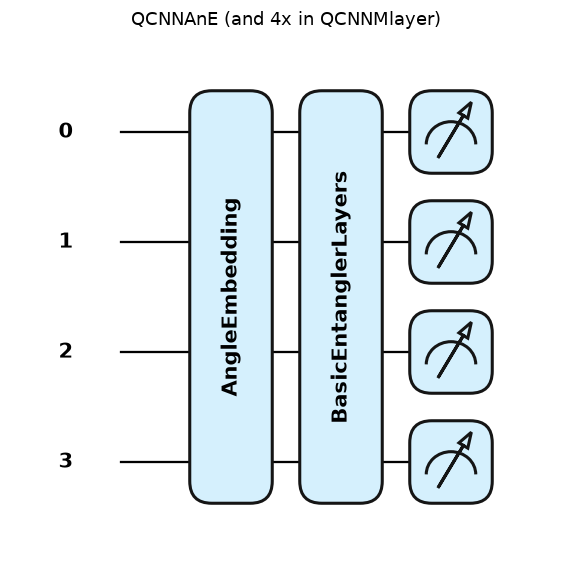

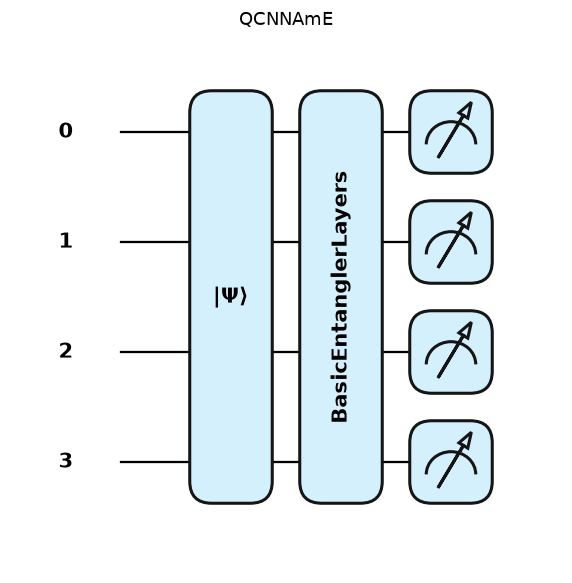

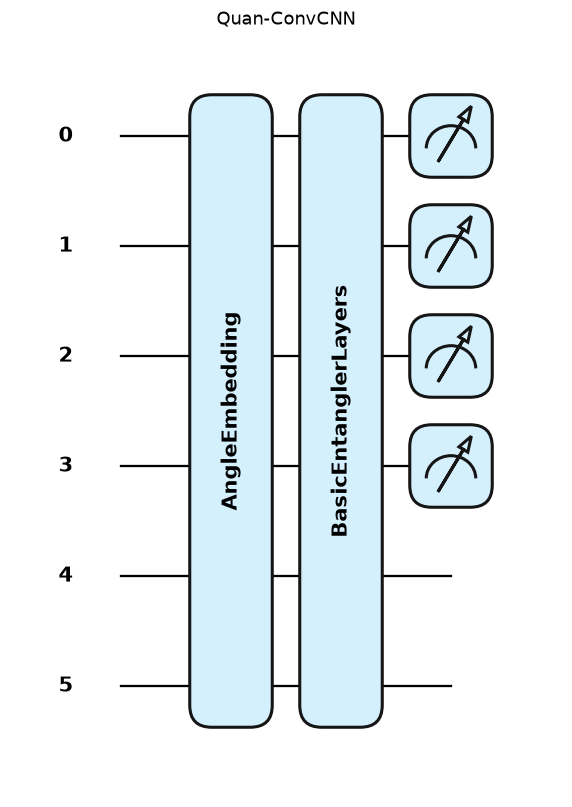

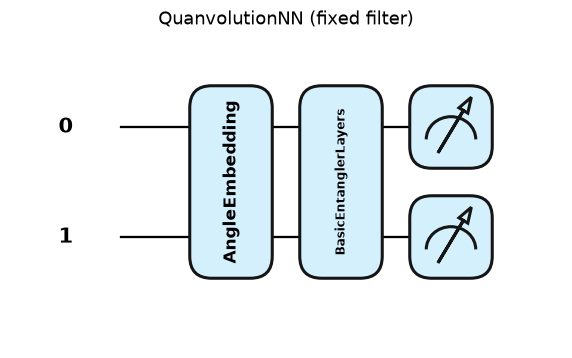

,qubits,depth (device level),gates,trainable parameters,fixed (frozen) parameters,max |QNode - simulator|
architecture,,,,,,
QCNNAnE (and 4x in QCNNMlayer),4,11,20,8,0,1.8e-07
QCNNAmE,4,11,17,8,0,1.5e-07
Quan-ConvCNN,6,15,30,12,0,9.4e-08
QuanvolutionNN (fixed filter),2,5,8,0,4,1.1e-07


QCNNMlayer = 4 independent copies of the QCNNAnE circuit -> 16 qubits, 4 x 8 = 32 trainable quantum parameters.


In [12]:
def make_qnode(n, emb, n_out):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch")
    def circuit(x, w):
        if emb == "angle":
            qml.AngleEmbedding(x, wires=range(n), rotation="X")
        else:
            qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
        qml.BasicEntanglerLayers(w, wires=range(n), rotation=qml.RX)
        return [qml.expval(qml.PauliZ(i)) for i in range(n_out)]      # only the read-out wires are measured
    return circuit

arch = {   # name -> (model kind, attribute holding the QLayer, qubits, embedding)
    "QCNNAnE (and 4x in QCNNMlayer)": ("ane", "q", 4, "angle"),
    "QCNNAmE": ("ame", "q", 4, "amplitude"),
    "Quan-ConvCNN": ("qconv", "q", 6, "angle"),
    "QuanvolutionNN (fixed filter)": ("quanv", "quanv", 2, "angle"),
}
rows = []
for name, (kind, attr, n, emb) in arch.items():
    net = HybridNet(kind, seed=SEED)
    ql = getattr(net, attr)
    qn = make_qnode(n, emb, ql.n_out)
    x = torch.rand(6, n if emb == "angle" else 2 ** n)
    ref = torch.stack([torch.stack(qn(xi, ql.weights.detach())) for xi in x]).float()
    sim = ql(x).detach()                                  # the model reads n_out wires (4 of 6 for Quan-ConvCNN)
    err = (ref - sim).abs().max().item()
    assert err < 1e-5, (name, err)                       # simulator == PennyLane QNode
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(x[0], ql.weights.detach())
    fig.suptitle(name, y=1.02); plt.show()
    spec = qml.specs(qn, level="device")(x[0], ql.weights.detach())
    res = spec["resources"]
    rows.append({"architecture": name, "qubits": n, "depth (device level)": res.depth,
                 "gates": res.num_gates, "trainable parameters": int(ql.weights.numel()) if ql.weights.requires_grad else 0,
                 "fixed (frozen) parameters": 0 if ql.weights.requires_grad else int(ql.weights.numel()),
                 "max |QNode - simulator|": f"{err:.1e}"})
display(pd.DataFrame(rows).set_index("architecture"))
print("QCNNMlayer = 4 independent copies of the QCNNAnE circuit -> 16 qubits, 4 x 8 = 32 trainable quantum parameters.")

In [13]:
rows = []
for m in MODEL_LABELS:
    net = HybridNet(m, seed=SEED)
    tr, q = n_params(net)
    rows.append({"model": MODEL_LABELS[m], "trainable parameters (total)": tr, "of which quantum": q})
print("Model sizes (the paper stresses that the models are kept small and comparable):")
display(pd.DataFrame(rows).set_index("model"))

Model sizes (the paper stresses that the models are kept small and comparable):


,trainable parameters (total),of which quantum
model,,
CNN,909,0
QCNNAnE,917,8
QCNNAmE,849,8
QCNNMlayer,885,32
Quan-ConvCNN,1187,12
QuanvolutionNN,653,0


In [14]:
MODELS = list(MODEL_LABELS)                     # cnn, ane, ame, mlayer, qconv, quanv

def tt(X, y):
    return torch.tensor(np.asarray(X), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.float32)

def scale_fit(Xtr, *others):
    """MinMax scaling to [0, 1] fitted on the training split only (paper: 'normalise to 0-1')."""
    sc = MinMaxScaler().fit(Xtr)
    return [sc.transform(a).astype(np.float32) for a in (Xtr,) + others]

def sample_balanced(frame, n_per_class, seed, exclude_index=None):
    """n_per_class benign + n_per_class malicious flows (CHOICE: malicious drawn uniformly from all
    malicious flows available, i.e. at the natural attack mix of that frame)."""
    if exclude_index is not None:
        frame = frame.drop(index=exclude_index)
    ben = frame[frame.y == 0].sample(n_per_class, random_state=seed)
    mal = frame[frame.y == 1].sample(n_per_class, random_state=seed)
    return pd.concat([ben, mal]).sample(frac=1.0, random_state=seed)

def run_models(models, Xtr, ytr, eval_sets, epochs, repeats, seed0, tag=""):
    """Train every model `repeats` times (different init / batch order); return {model: [hist, ...]}."""
    out = {m: [] for m in models}
    majority = max(ytr.mean().item(), 1 - ytr.mean().item())
    for m in models:
        for r in range(repeats):
            # The paper discards runs that get stuck in a trivial local minimum ("the model stacks at
            # 91.5 % and does not improve") and repeats them. Same rule here: a run whose final training
            # accuracy is not above the majority-class rate is re-run with a new seed (max. 3 retries).
            for attempt in range(4):
                h, sec, net = train_model(m, Xtr, ytr, eval_sets, epochs, seed=seed0 + 100 * r + 7 * attempt)
                if h["train_acc"][-1] > majority + 0.01:
                    break
                print(f"{tag} {MODEL_LABELS[m]:<14s} run {r + 1}: degenerate (train acc {h['train_acc'][-1]:.3f} "
                      f"<= majority {majority:.3f}); discarded, re-running", flush=True)
                DISCARDED[m] = DISCARDED.get(m, 0) + 1
            h["seconds"] = sec
            out[m].append(h)
            keys = [k for k in eval_sets]
            print(f"{tag} {MODEL_LABELS[m]:<14s} run {r + 1}/{repeats}  {sec:5.1f}s  " +
                  "  ".join(f"{k}={h[k][-1]*100:5.2f}%" for k in keys), flush=True)
    return out

DISCARDED = {}                                  # model -> number of degenerate runs discarded

def final_table(res, key):
    rows = []
    for m, hs in res.items():
        a = np.array([h[key][-1] for h in hs]) * 100
        rows.append({"model": MODEL_LABELS[m], "mean": a.mean(), "std": a.std(), "runs": ", ".join(f"{v:.2f}" for v in a),
                     "sec/run": np.mean([h["seconds"] for h in hs])})
    return pd.DataFrame(rows).set_index("model")

def plot_curves(res, key, title, ax=None):
    ax = ax or plt.gca()
    for m, hs in res.items():
        a = np.mean([h[key] for h in hs], 0) * 100
        ax.plot(np.arange(1, len(a) + 1), a, label=MODEL_LABELS[m], lw=1.6, marker="o" if len(a) < 12 else None, ms=3)
    ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy (%)"); ax.set_title(title); ax.grid(alpha=.3)
    ax.legend(fontsize=8)

# Experiment 3 -----------------------------------------------------------------------------------
UNSEEN_GROUPS = {"UDPFlood": ["UDPFlood"],
                 "Remain": ["TCPConnectScan", "SYNScan", "UDPScan", "SYNFlood", "ICMPFlood"],
                 "HTTPFlood": ["HTTPFlood"],
                 "SlowrateDoS": ["SlowrateDoS"]}

def make_exp3(df, group, n_train_per_class, n_hold_per_class, n_unseen, seed):
    unseen_types = UNSEEN_GROUPS[group]
    seen = df[~df["Attack Type"].isin(unseen_types)]
    unseen = df[df["Attack Type"].isin(unseen_types)]
    tr = sample_balanced(seen, n_train_per_class, seed)
    ho = sample_balanced(seen, n_hold_per_class, seed + 1, exclude_index=tr.index)
    un = unseen.sample(min(n_unseen, len(unseen)), random_state=seed)
    Xtr, Xho, Xun = scale_fit(tr[FEATURES].values, ho[FEATURES].values, un[FEATURES].values)
    return (tt(Xtr, tr.y), {"existing": tt(Xho, ho.y), "unseen": tt(Xun, un.y)}, tr, ho, un)

def tradeoff_epoch(existing, unseen):
    """Paper: trade-off point = intersection of the seen-data and unseen-data accuracy curves
    (model initially calls every test flow malicious); if the curves never cross, the epoch with the
    smallest absolute gap."""
    gap = np.abs(np.array(existing) - np.array(unseen))
    return int(np.argmin(gap))

def exp3_summary(res):
    rows = []
    for m, hs in res.items():
        fin_u = np.mean([h["unseen"][-1] for h in hs]) * 100
        fin_e = np.mean([h["existing"][-1] for h in hs]) * 100
        te = [tradeoff_epoch(h["existing"], h["unseen"]) for h in hs]
        tr_u = np.mean([h["unseen"][e] for h, e in zip(hs, te)]) * 100
        tr_e = np.mean([h["existing"][e] for h, e in zip(hs, te)]) * 100
        rows.append({"model": MODEL_LABELS[m], "final_unseen": fin_u, "final_existing": fin_e,
                     "trade_unseen": tr_u, "trade_existing": tr_e, "trade_epoch": np.mean(te) + 1})
    return pd.DataFrame(rows).set_index("model")

## 4. Experiment 1: standard random 70/30 split (Table IV)

A random sample of the whole dataset (natural class mix: about 61 % attacks) is split 70/30 (stratified by attack type). The MinMax scaler is fitted on the training part. All six networks are trained for `EPOCHS` epochs, `rep12` times each (different initial weights and batch order). The Random Forest and the RBF-SVC are classical references on exactly the same 28 normalised inputs.

In [15]:
b = BUDGET
s1 = df.sample(b["n1"], random_state=SEED)
tr1, te1 = train_test_split(s1, test_size=0.3, random_state=SEED, stratify=s1["Attack Type"])
X1tr, X1te = scale_fit(tr1[FEATURES].values, te1[FEATURES].values)
Xt, yt = tt(X1tr, tr1.y); Xe, ye = tt(X1te, te1.y)
print(f"Exp.1: train {len(tr1):,} / test {len(te1):,} flows; attack share train {tr1.y.mean():.3f}")
t0 = time.time()
res1 = run_models(MODELS, Xt, yt, {"test": (Xe, ye)}, EPOCHS, b["rep12"], SEED, tag="Exp1")
print(f"Exp.1 finished in {(time.time() - t0) / 60:.1f} min")
tab1 = final_table(res1, "test"); display(tab1.round(2))

Exp.1: train 3,500 / test 1,500 flows; attack share train 0.599


Exp1 CNN            run 1/3   32.7s  test=89.07%


Exp1 CNN            run 2/3   40.4s  test=89.13%


Exp1 CNN            run 3/3   38.1s  test=88.47%


Exp1 QCNNAnE        run 1/3   59.3s  test=88.53%


...

Exp1 QuanvolutionNN run 1/3   26.1s  test=82.53%


Exp1 QuanvolutionNN run 2/3   20.8s  test=87.60%


Exp1 QuanvolutionNN run 3/3   21.1s  test=87.40%


Exp.1 finished in 20.4 min


,mean,std,runs,sec/run
model,,,,
CNN,88.89,0.30,"89.07, 89.13, 88.47",37.05
QCNNAnE,88.78,0.60,"88.53, 89.60, 88.20",57.17
QCNNAmE,80.58,9.38,"67.33, 87.80, 86.60",41.10
QCNNMlayer,87.76,0.49,"87.67, 87.20, 88.40",101.16
Quan-ConvCNN,87.93,0.47,"87.67, 87.53, 88.60",74.78
QuanvolutionNN,85.84,2.34,"82.53, 87.60, 87.40",22.63


{'RandomForest': (95.53, '5s'), 'SVC(rbf, 3500 train)': (88.6, '2s')}
trivial baseline (always say attack): 59.87 %


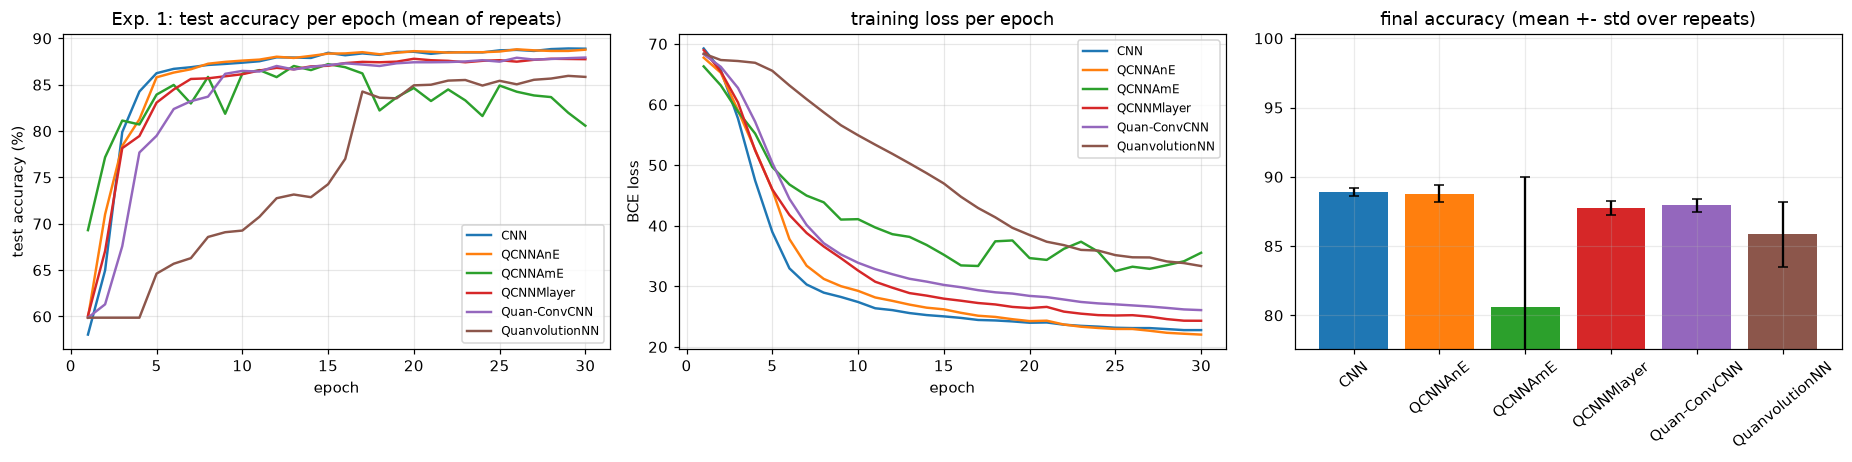

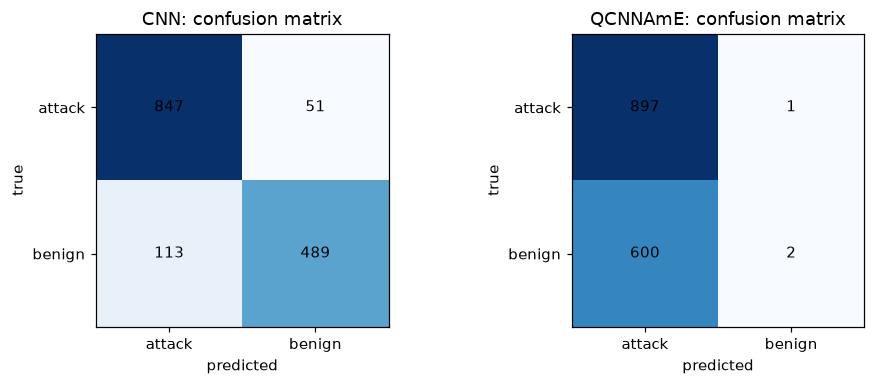

In [16]:
def classical_refs(Xtr, ytr, Xte, yte, svc_max, seed=SEED):
    out = {}
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2).fit(Xtr, ytr)
    out["RandomForest"] = (accuracy_score(yte, rf.predict(Xte)) * 100, time.time() - t0)
    n = min(len(Xtr), svc_max); t0 = time.time()
    svc = SVC(kernel="rbf", random_state=seed).fit(Xtr[:n], ytr[:n])
    out[f"SVC(rbf, {n} train)"] = (accuracy_score(yte, svc.predict(Xte)) * 100, time.time() - t0)
    return out

ref1 = classical_refs(X1tr, tr1.y.values, X1te, te1.y.values, b["svc_max"])
print({k: (round(v[0], 2), f"{v[1]:.0f}s") for k, v in ref1.items()})
print(f"trivial baseline (always say attack): {100 * te1.y.mean():.2f} %")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
plot_curves(res1, "test", "Exp. 1: test accuracy per epoch (mean of repeats)", ax[0])
plot_curves(res1, "loss", "training loss per epoch", ax[1]); ax[1].set_ylabel("BCE loss")
for m, hs in res1.items():
    ax[2].bar(MODEL_LABELS[m], np.mean([h["test"][-1] for h in hs]) * 100, yerr=np.std([h["test"][-1] for h in hs]) * 100, capsize=3)
ax[2].set_ylim(max(0, tab1["mean"].min() - 3), 100.3); ax[2].set_title("final accuracy (mean +- std over repeats)")
ax[2].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

# confusion matrix of one trained model (attack = positive class), first model of each family
cm_models = ["cnn", "ame"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, m in zip(ax, cm_models):
    _, _, net = train_model(m, Xt, yt, {}, EPOCHS, seed=SEED)
    net.eval()
    with torch.no_grad():
        pred = (net(Xe) > 0).int().numpy()
    cm = confusion_matrix(ye.numpy().astype(int), pred, labels=[1, 0])
    a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_xticklabels(["attack", "benign"]); a.set_yticks([0, 1]); a.set_yticklabels(["attack", "benign"])
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center")
    a.set_title(f"{MODEL_LABELS[m]}: confusion matrix"); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
plt.tight_layout(); plt.show()

## 5. Experiment 2: train on one base station, test on the other (Tables V and VI)

* **2.1**: train on BS1 (large, balanced benign/malicious subsample), test on a random subsample of BS2.
* **2.2**: train on BS2 (small, balanced), test on a random subsample of BS1. The paper stresses that BS2 offers much less benign data than BS1, so the training set is about 4.5 times smaller.

The test sets keep the natural class mix of the other base station (BS2: 86 % attacks; BS1: 44 % attacks), so a model that is biased towards "attack" still scores high on 2.1.

In [17]:
def run_exp2(src_bs, dst_bs, n_per_class, tag):
    src, dst = df[df.BS == src_bs], df[df.BS == dst_bs]
    tr = sample_balanced(src, n_per_class, SEED)
    te = dst.sample(min(b["n_test2"], len(dst)), random_state=SEED)
    Xtr_, Xte_ = scale_fit(tr[FEATURES].values, te[FEATURES].values)
    Xa, ya = tt(Xtr_, tr.y); Xb, yb = tt(Xte_, te.y)
    print(f"{tag}: train BS{src_bs} {len(tr):,} (balanced) -> test BS{dst_bs} {len(te):,} (attack share {te.y.mean():.2f})")
    res = run_models(MODELS, Xa, ya, {"test": (Xb, yb)}, EPOCHS, b["rep12"], SEED, tag=tag)
    ref = classical_refs(Xtr_, tr.y.values, Xte_, te.y.values, b["svc_max"])
    return res, ref

n2a = b["n2"]; n2b = max(200, int(round(n2a / 4.5)))      # BS2 offers 70,778 benign flows vs 406,959 in BS1 (ratio 5.7; balanced sets ratio ~4.5)
res21, ref21 = run_exp2(1, 2, n2a, "Exp2.1")
tab21 = final_table(res21, "test"); display(tab21.round(2)); print({k: round(v[0], 2) for k, v in ref21.items()}, "| trivial always-attack baseline = BS2 attack share =", round(100 * df[df.BS == 2].y.mean(), 1), "%")
res22, ref22 = run_exp2(2, 1, n2b, "Exp2.2")
tab22 = final_table(res22, "test"); display(tab22.round(2)); print({k: round(v[0], 2) for k, v in ref22.items()}, "| trivial always-attack baseline = BS1 attack share =", round(100 * df[df.BS == 1].y.mean(), 1), "%")

Exp2.1: train BS1 4,000 (balanced) -> test BS2 5,000 (attack share 0.85)


Exp2.1 CNN            run 1/3   44.6s  test=77.22%


Exp2.1 CNN            run 2/3   46.9s  test=78.04%


Exp2.1 CNN            run 3/3   46.3s  test=78.86%


Exp2.1 QCNNAnE        run 1/3   59.0s  test=76.68%


...

Exp2.2 QuanvolutionNN run 2/3   10.1s  test=56.36%


Exp2.2 QuanvolutionNN run 3: degenerate (train acc 0.500 <= majority 0.500); discarded, re-running


Exp2.2 QuanvolutionNN run 3/3    8.7s  test=58.32%


,mean,std,runs,sec/run
model,,,,
CNN,58.15,0.44,"57.68, 58.02, 58.74",17.70
QCNNAnE,53.85,5.82,"45.62, 57.82, 58.12",17.38
QCNNAmE,44.61,20.23,"52.86, 16.76, 64.22",16.85
QCNNMlayer,61.59,8.18,"54.40, 57.34, 73.04",26.37
Quan-ConvCNN,57.40,0.07,"57.48, 57.32, 57.40",33.78
QuanvolutionNN,56.75,1.15,"55.58, 56.36, 58.32",9.34


{'RandomForest': 61.88, 'SVC(rbf, 888 train)': 58.12} | trivial always-attack baseline = BS1 attack share = 44.1 %


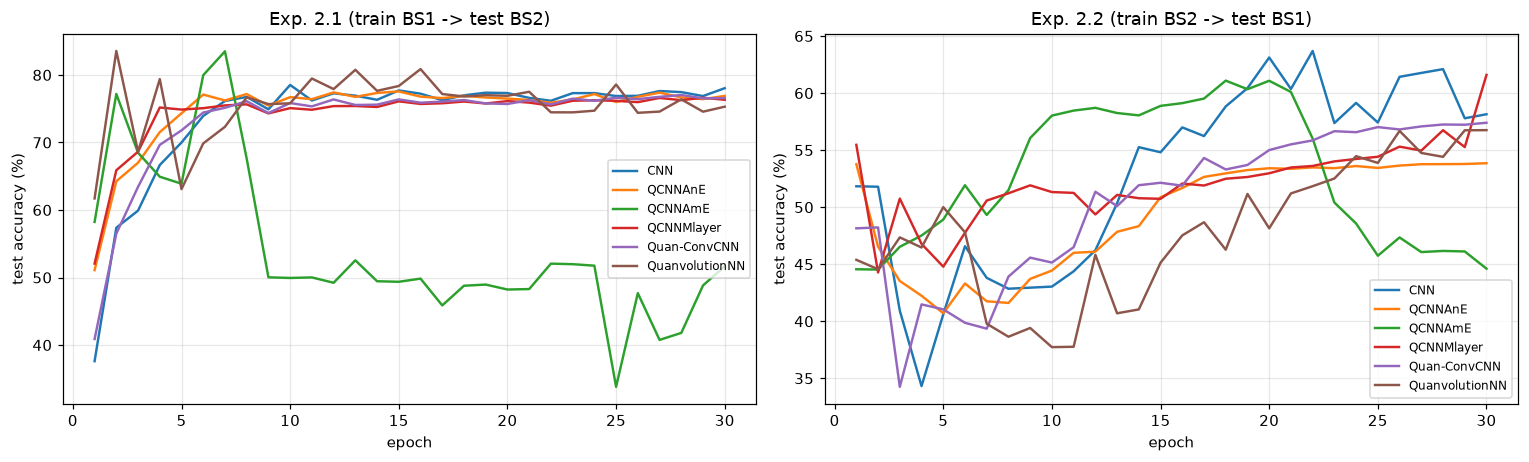

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
plot_curves(res21, "test", "Exp. 2.1 (train BS1 -> test BS2)", ax[0])
plot_curves(res22, "test", "Exp. 2.2 (train BS2 -> test BS1)", ax[1])
plt.tight_layout(); plt.show()

## 6. Experiment 3: an attack type that was never seen in training (Tables IX, X)

Four tests: **UDPFlood**, **HTTPFlood**, **SlowrateDoS** and **Remain** (the five small attack types pooled), each held out in turn. QCNNMlayer is excluded, as in the paper. For every run we record the accuracy on (a) a held-out balanced set of *seen* traffic ("existing attack" column) and (b) the unseen-attack flows (all malicious, so this is the share called malicious) after each epoch. Then we report both the final-epoch values (Table IX) and the values at the **trade-off epoch** where the two curves cross (Table X; smallest gap if they do not cross).

In [19]:
M3 = ["cnn", "ane", "ame", "qconv", "quanv"]
res3, info3 = {}, {}
t0 = time.time()
for g in UNSEEN_GROUPS:
    (Xa, ya), sets, tr_, ho_, un_ = make_exp3(df, g, b["n3"], b["n3_hold"], b["n3_unseen"], SEED)
    info3[g] = (len(tr_), len(ho_), len(un_))
    print(f"[{g}] train {len(tr_):,} balanced | held-out seen {len(ho_):,} | unseen {len(un_):,} flows of {UNSEEN_GROUPS[g]}")
    res3[g] = run_models(M3, Xa, ya, sets, EPOCHS, b["rep3"], SEED, tag=f"Exp3[{g}]")
print(f"Exp.3 finished in {(time.time() - t0) / 60:.1f} min")
sum3 = {g: exp3_summary(r) for g, r in res3.items()}
for g, t in sum3.items():
    print(f"\n== unseen: {g} =="); display(t.round(2))

[UDPFlood] train 2,000 balanced | held-out seen 1,000 | unseen 1,000 flows of ['UDPFlood']


Exp3[UDPFlood] CNN            run 1/3   13.7s  existing=97.60%  unseen= 3.30%


Exp3[UDPFlood] CNN            run 2/3   14.8s  existing=98.60%  unseen= 6.90%


Exp3[UDPFlood] CNN            run 3/3   14.3s  existing=97.30%  unseen=12.90%


Exp3[UDPFlood] QCNNAnE        run 1/3   22.3s  existing=97.70%  unseen= 2.90%


...

,final_unseen,final_existing,trade_unseen,trade_existing,trade_epoch
model,,,,,
CNN,99.37,86.83,81.80,79.90,20.00
QCNNAnE,98.67,86.70,98.57,87.63,28.67
QCNNAmE,16.30,74.30,86.27,88.83,14.33
Quan-ConvCNN,86.87,87.67,95.37,87.47,24.67
QuanvolutionNN,99.90,86.13,86.10,82.00,19.67



== unseen: HTTPFlood ==


,final_unseen,final_existing,trade_unseen,trade_existing,trade_epoch
model,,,,,
CNN,63.60,87.13,76.30,81.30,9.67
QCNNAnE,66.23,87.07,73.97,76.10,3.67
QCNNAmE,73.87,83.53,80.23,80.83,16.00
Quan-ConvCNN,62.33,87.23,73.00,75.00,5.67
QuanvolutionNN,82.63,86.77,85.07,83.00,17.33



== unseen: SlowrateDoS ==


,final_unseen,final_existing,trade_unseen,trade_existing,trade_epoch
model,,,,,
CNN,99.80,87.47,96.67,87.97,19.67
QCNNAnE,99.80,87.80,99.80,88.17,26.67
QCNNAmE,99.93,73.33,81.77,78.17,16.33
Quan-ConvCNN,99.93,87.47,99.93,87.90,27.67
QuanvolutionNN,100.00,86.23,84.23,77.20,17.00


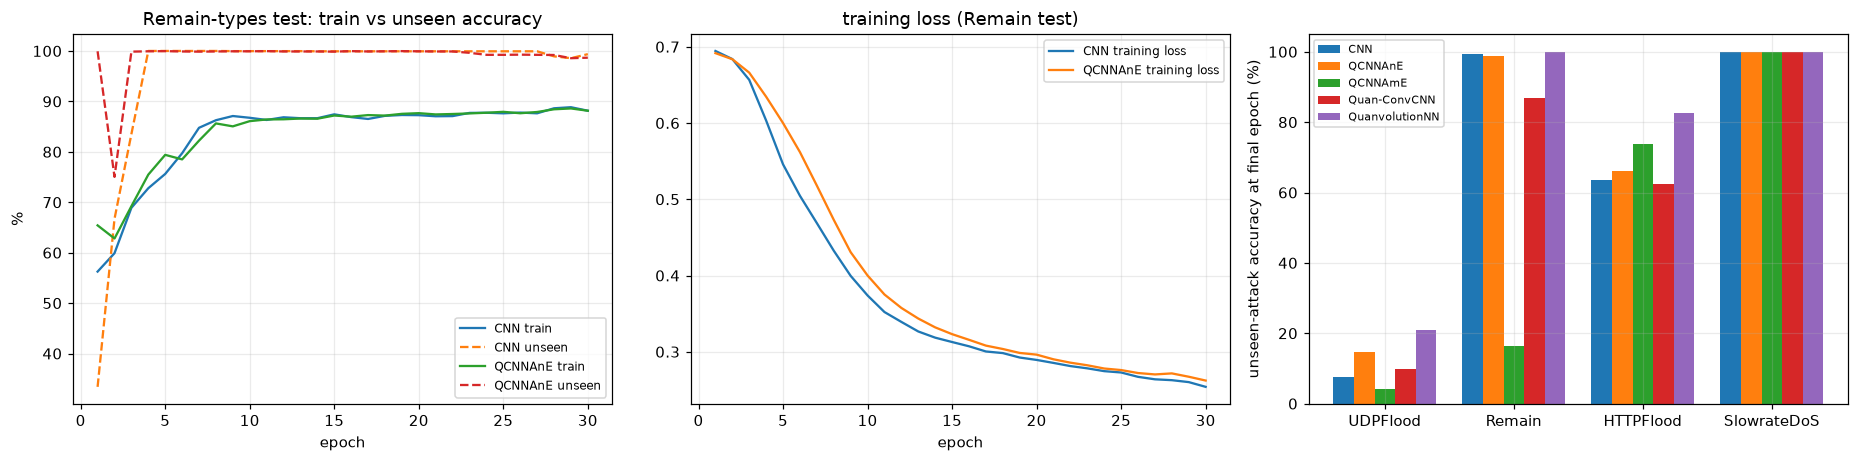

,RF existing %,RF unseen %
unseen attack,,
UDPFlood,99.8,1.4
Remain,94.0,34.3
HTTPFlood,95.2,96.5
SlowrateDoS,94.6,100.0


In [20]:
# Exp.3 curves (paper Fig. 14/15 style) for the Remain-types test and the classical Random-Forest reference
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
g = "Remain"
for m in ["cnn", "ane"]:
    hs = res3[g][m]
    ax[0].plot(np.arange(1, EPOCHS + 1), np.mean([h["train_acc"] for h in hs], 0) * 100, label=f"{MODEL_LABELS[m]} train")
    ax[0].plot(np.arange(1, EPOCHS + 1), np.mean([h["unseen"] for h in hs], 0) * 100, "--", label=f"{MODEL_LABELS[m]} unseen")
ax[0].set_title("Remain-types test: train vs unseen accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("%"); ax[0].legend(fontsize=8)
for m in ["cnn", "ane"]:
    hs = res3[g][m]
    ax[1].plot(np.arange(1, EPOCHS + 1), np.mean([h["loss"] for h in hs], 0), label=f"{MODEL_LABELS[m]} training loss")
ax[1].set_title("training loss (Remain test)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
x_ = np.arange(len(UNSEEN_GROUPS)); w_ = 0.16
for i, m in enumerate(M3):
    ax[2].bar(x_ + (i - 2) * w_, [sum3[g_].loc[MODEL_LABELS[m], "final_unseen"] for g_ in UNSEEN_GROUPS], w_, label=MODEL_LABELS[m])
ax[2].set_xticks(x_); ax[2].set_xticklabels(list(UNSEEN_GROUPS)); ax[2].set_ylabel("unseen-attack accuracy at final epoch (%)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# Classical Random-Forest reference on the same unseen-attack splits (single run)
rf_rows = []
for g in UNSEEN_GROUPS:
    (Xa, ya), sets, *_ = make_exp3(df, g, b["n3"], b["n3_hold"], b["n3_unseen"], SEED)
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2).fit(Xa.numpy(), ya.numpy())
    rf_rows.append({"unseen attack": g, "RF existing %": 100 * rf.score(*(t.numpy() for t in sets["existing"])),
                    "RF unseen %": 100 * rf.score(*(t.numpy() for t in sets["unseen"]))})
display(pd.DataFrame(rf_rows).set_index("unseen attack").round(2))

## 7. Side-by-side comparison with the paper

`paper` columns are copied from the paper's Tables IV, V, VI, IX and X. Verdict rule for a single cell: **reproduced** if our mean is within 2 accuracy points of the paper's value, otherwise **exceeded** (we are higher) or **not reached** (we are lower). The qualitative claims at the end are judged from our own means and spread.

In [21]:
PAPER = {
 "exp1":  {"CNN": 99.61, "QCNNAnE": 99.62, "QCNNAmE": 99.65, "QCNNMlayer": 98.89, "Quan-ConvCNN": 99.71, "QuanvolutionNN": 98.67},
 "exp21": {"CNN": 78.23, "QCNNAnE": 78.30, "QCNNAmE": 78.81, "QCNNMlayer": 78.54, "Quan-ConvCNN": 78.93, "QuanvolutionNN": 78.66},
 "exp22": {"CNN": 74.28, "QCNNAnE": 59.36, "QCNNAmE": 81.57, "QCNNMlayer": 69.70, "Quan-ConvCNN": 64.07, "QuanvolutionNN": 57.18},
}
# Tables IX (final epoch) and X (trade-off): (unseen, existing) per model and test
PAPER9 = {"UDPFlood":   {"CNN": (9.52, 99.70), "QCNNAnE": (15.19, 99.68), "QCNNAmE": (36.38, 95.36), "Quan-ConvCNN": (13.62, 99.61), "QuanvolutionNN": (24.52, 99.20)},
          "Remain":     {"CNN": (83.72, 92.07), "QCNNAnE": (76.28, 92.41), "QCNNAmE": (84.10, 91.00), "Quan-ConvCNN": (87.84, 92.29), "QuanvolutionNN": (87.27, 90.76)},
          "HTTPFlood":  {"CNN": (55.63, 92.08), "QCNNAnE": (59.33, 91.15), "QCNNAmE": (45.14, 91.61), "Quan-ConvCNN": (51.64, 91.66), "QuanvolutionNN": (58.88, 90.14)},
          "SlowrateDoS":{"CNN": (79.85, 92.76), "QCNNAnE": (82.90, 92.47), "QCNNAmE": (82.05, 91.30), "Quan-ConvCNN": (75.00, 92.21), "QuanvolutionNN": (88.30, 90.12)}}
PAPER10 = {"UDPFlood": {"CNN": (32.82, 92.05), "QCNNAnE": (18.47, 98.55), "QCNNAmE": (48.55, 96.40), "Quan-ConvCNN": (30.12, 96.08), "QuanvolutionNN": (41.83, 85.93)},
           "Remain":  {"CNN": (91.44, 91.46), "QCNNAnE": (91.75, 91.59), "QCNNAmE": (93.64, 90.73), "Quan-ConvCNN": (92.31, 91.82), "QuanvolutionNN": (91.85, 90.58)},
           "HTTPFlood": {"CNN": (65.78, 87.63), "QCNNAnE": (67.56, 87.87), "QCNNAmE": (58.90, 83.51), "Quan-ConvCNN": (66.44, 87.19), "QuanvolutionNN": (67.78, 85.77)},
           "SlowrateDoS": {"CNN": (91.82, 91.78), "QCNNAnE": (92.45, 92.32), "QCNNAmE": (90.86, 90.17), "Quan-ConvCNN": (91.08, 90.99), "QuanvolutionNN": (90.15, 90.05)}}

def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
for key, tab, name in [("exp1", tab1, "Exp.1 (Table IV)"), ("exp21", tab21, "Exp.2.1 (Table V)"), ("exp22", tab22, "Exp.2.2 (Table VI)")]:
    for model, pv in PAPER[key].items():
        if model in tab.index:
            o = tab.loc[model, "mean"]
            rows.append({"claim": name, "model": model, "paper %": pv, "notebook %": round(o, 2), "std": round(tab.loc[model, "std"], 2),
                         "diff": round(o - pv, 2), "verdict": verdict(o, pv)})
for tname, PT, col in [("Exp.3 final epoch (Table IX)", PAPER9, "final"), ("Exp.3 trade-off (Table X)", PAPER10, "trade")]:
    for g in UNSEEN_GROUPS:
        for model, (pu, pe) in PT[g].items():
            ou, oe = sum3[g].loc[model, f"{col}_unseen"], sum3[g].loc[model, f"{col}_existing"]
            rows.append({"claim": f"{tname} unseen={g}: unseen acc", "model": model, "paper %": pu, "notebook %": round(ou, 2), "std": np.nan,
                         "diff": round(ou - pu, 2), "verdict": verdict(ou, pu)})
            rows.append({"claim": f"{tname} unseen={g}: existing acc", "model": model, "paper %": pe, "notebook %": round(oe, 2), "std": np.nan,
                         "diff": round(oe - pe, 2), "verdict": verdict(oe, pe)})
cmp_df = pd.DataFrame(rows)
pd.set_option("display.width", 200, "display.max_rows", 400, "display.max_colwidth", 60)
display(cmp_df[cmp_df.claim.str.startswith("Exp.1") | cmp_df.claim.str.startswith("Exp.2")])
print(cmp_df.groupby(cmp_df.claim.str.extract(r"^(Exp\.[0-9.]+(?: final epoch| trade-off)?)")[0])["verdict"].value_counts().unstack(fill_value=0))

,claim,model,paper %,notebook %,std,diff,verdict
0,Exp.1 (Table IV),CNN,99.61,88.89,0.30,-10.72,not reached
1,Exp.1 (Table IV),QCNNAnE,99.62,88.78,0.60,-10.84,not reached
2,Exp.1 (Table IV),QCNNAmE,99.65,80.58,9.38,-19.07,not reached
3,Exp.1 (Table IV),QCNNMlayer,98.89,87.76,0.49,-11.13,not reached
4,Exp.1 (Table IV),Quan-ConvCNN,99.71,87.93,0.47,-11.78,not reached
5,Exp.1 (Table IV),QuanvolutionNN,98.67,85.84,2.34,-12.83,not reached
6,Exp.2.1 (Table V),CNN,78.23,78.04,0.67,-0.19,reproduced
7,Exp.2.1 (Table V),QCNNAnE,78.30,76.90,0.19,-1.40,reproduced
8,Exp.2.1 (Table V),QCNNAmE,78.81,51.69,26.61,-27.12,not reached
9,Exp.2.1 (Table V),QCNNMlayer,78.54,76.32,1.25,-2.22,not reached


verdict            exceeded  not reached  reproduced
0                                                   
Exp.1                     0            6           0
Exp.2.1                   0            4           2
Exp.2.2                   0            5           1
Exp.3 final epoch        13           21           6
Exp.3 trade-off          14           25           1


In [22]:
display(cmp_df[cmp_df.claim.str.startswith("Exp.3")].pivot_table(index=["claim"], columns="model", values="diff").round(1))

model,CNN,QCNNAmE,QCNNAnE,Quan-ConvCNN,QuanvolutionNN
claim,,,,,
Exp.3 final epoch (Table IX) unseen=HTTPFlood: existing acc,-5.0,-8.1,-4.1,-4.4,-3.4
Exp.3 final epoch (Table IX) unseen=HTTPFlood: unseen acc,8.0,28.7,6.9,10.7,23.8
Exp.3 final epoch (Table IX) unseen=Remain: existing acc,-5.2,-16.7,-5.7,-4.6,-4.6
Exp.3 final epoch (Table IX) unseen=Remain: unseen acc,15.6,-67.8,22.4,-1.0,12.6
Exp.3 final epoch (Table IX) unseen=SlowrateDoS: existing acc,-5.3,-18.0,-4.7,-4.7,-3.9
Exp.3 final epoch (Table IX) unseen=SlowrateDoS: unseen acc,20.0,17.9,16.9,24.9,11.7
Exp.3 final epoch (Table IX) unseen=UDPFlood: existing acc,-1.9,-12.9,-1.6,-1.7,-2.2
Exp.3 final epoch (Table IX) unseen=UDPFlood: unseen acc,-1.8,-32.2,-0.7,-3.8,-3.6
Exp.3 trade-off (Table X) unseen=HTTPFlood: existing acc,-6.3,-2.7,-11.8,-12.2,-2.8


In [23]:
# Qualitative claims of the paper, judged from this notebook's own numbers
print("Degenerate runs discarded and re-run (stuck at a trivial minimum), by model:", {MODEL_LABELS[k]: v for k, v in DISCARDED.items()})
def mean_of(tab, model): return tab.loc[model, "mean"]
def better(tab, model, base="CNN"): return mean_of(tab, model) > mean_of(tab, base)
claims = []
q_models = ["QCNNAnE", "QCNNAmE", "Quan-ConvCNN"]
claims.append(("Exp.1: most hybrid QCNNs are at least as good as the CNN (paper: 4 of 5 are higher)",
               f"{sum(better(tab1, m) for m in tab1.index if m != 'CNN')} of 5 higher; CNN {mean_of(tab1,'CNN'):.2f} %, best hybrid {tab1.drop('CNN')['mean'].max():.2f} %, spread (std) up to {tab1['std'].max():.2f}",
               "reproduced" if sum(better(tab1, m) for m in tab1.index if m != 'CNN') >= 3 else "not reached"))
claims.append(("Exp.1: Quan-ConvCNN best, QuanvolutionNN and QCNNMlayer lowest",
               f"best: {tab1['mean'].idxmax()}; lowest: {tab1['mean'].idxmin()}",
               "reproduced" if tab1['mean'].idxmax() == "Quan-ConvCNN" and tab1['mean'].idxmin() in ("QuanvolutionNN", "QCNNMlayer") else "not reached"))
claims.append(("Exp.2.1: all models within about 1 point of each other near 78 %",
               f"range {tab21['mean'].min():.2f} - {tab21['mean'].max():.2f} %",
               "reproduced" if tab21['mean'].max() - tab21['mean'].min() <= 2 else "not reached"))
claims.append(("Exp.2.1: every hybrid beats the CNN", f"{sum(better(tab21, m) for m in tab21.index if m != 'CNN')} of 5 higher",
               "reproduced" if all(better(tab21, m) for m in tab21.index if m != 'CNN') else "not reached"))
claims.append(("Exp.2.2: QCNNAmE best (81.57 %), angle-embedding hybrids worse than the CNN",
               f"best: {tab22['mean'].idxmax()} ({tab22['mean'].max():.2f}); CNN {mean_of(tab22,'CNN'):.2f}; AnE {mean_of(tab22,'QCNNAnE'):.2f}",
               "reproduced" if tab22['mean'].idxmax() == "QCNNAmE" and mean_of(tab22, 'QCNNAnE') < mean_of(tab22, 'CNN') else "not reached"))
cnn_u = {g: sum3[g].loc["CNN", "final_unseen"] for g in sum3}
nb = sum(any(sum3[g].loc[MODEL_LABELS[m], "final_unseen"] > cnn_u[g] for m in ["ane", "ame", "qconv", "quanv"]) for g in sum3)
claims.append(("Exp.3: in each unseen-attack test at least one QCNN beats the CNN (final epoch)",
               f"{nb} of 4 tests", "reproduced" if nb == 4 else "not reached"))
claims.append(("Exp.3: UDPFlood stays hard (no model above 50 % unseen accuracy, final epoch)",
               f"best unseen accuracy {sum3['UDPFlood']['final_unseen'].max():.1f} %", "reproduced" if sum3['UDPFlood']['final_unseen'].max() < 50 else "not reached"))
claims.append(("Overall: 'QCNNs outperform the classical CNN' in general",
               "see all tables above: gaps are mostly inside the run-to-run spread of this and of the paper's appendix",
               "cannot be checked (not statistically separable at this scale)"))
print(pd.DataFrame(claims, columns=["paper claim", "this notebook", "verdict"]).to_string(index=False, justify="left", max_colwidth=90))

Degenerate runs discarded and re-run (stuck at a trivial minimum), by model: {'QCNNAmE': 6, 'QuanvolutionNN': 12, 'QCNNAnE': 1}
paper claim                                                                         this notebook                                                                              verdict                                                      
Exp.1: most hybrid QCNNs are at least as good as the CNN (paper: 4 of 5 are higher)                   0 of 5 higher; CNN 88.89 %, best hybrid 88.78 %, spread (std) up to 9.38                                                   not reached
                     Exp.1: Quan-ConvCNN best, QuanvolutionNN and QCNNMlayer lowest                                                                 best: CNN; lowest: QCNNAmE                                                   not reached
                   Exp.2.1: all models within about 1 point of each other near 78 %                                                                      range 51

### Summary of the committed run (`FAST_MODE = False`)

Numbers are means over 3 runs (Exp. 1, 2) on a few thousand flows per experiment, 30 epochs; the paper uses 851,123 training flows. Read them together with the standard deviations printed above.

| | CNN | QCNNAnE | QCNNAmE | QCNNMlayer | Quan-ConvCNN | QuanvolutionNN | Random Forest | paper CNN / best QCNN |
|---|---|---|---|---|---|---|---|---|
| Exp. 1 (random split) | 88.9 | 88.8 | 80.6 | 87.8 | 87.9 | 85.8 | 95.5 | 99.61 / 99.71 |
| Exp. 2.1 (BS1 -> BS2) | 78.0 | 76.9 | 51.7 | 76.3 | 76.6 | 75.3 | 77.7 | 78.23 / 78.93 |
| Exp. 2.2 (BS2 -> BS1) | 58.2 | 53.9 | 44.6 | 61.6 | 57.4 | 56.8 | 61.9 | 74.28 / 81.57 |

* **Level.** Experiment 1 stays about 11 points under the paper because our networks see about 0.4 % of the training flows (a Random Forest on the same 3,500 flows reaches 95.5 %, the paper's 99.6 % needs the full data). Experiment 2.1 lands on the paper's level (CNN 78.0 vs 78.2); a Random Forest scores the same, so this number mostly reflects the base-station shift and the 85 % attack share of BS2 (always saying "attack" gives 85.5 %).
* **Ranking.** In this run no hybrid beats the CNN in Experiments 1 and 2.1 (differences of 1 point or less are inside the run-to-run spread). QCNNAmE is the least stable model: 2 of 3 Exp. 2.1 runs collapse to 30-36 %. The paper's headline Exp. 2.2 result (QCNNAmE best at 81.57 %) is **not** reproduced; the angle-embedding models being worse than the CNN in the small-data case partly is (QCNNAnE 53.9 vs CNN 58.2).
* **Unseen attacks.** The picture matches the paper's qualitative statements: UDP-Flood is by far the hardest unseen attack (every model under 21 % at the final epoch, Random Forest 1.4 %), SlowrateDoS and the pooled Remain types are detected almost fully by most models (QCNNAmE fails on Remain, 16 %; see the caveat on what this accuracy means in section 8). In each of the four tests at least one QCNN is above the CNN at the final epoch, but differences are within the large run-to-run spread, so "QCNNs generalise better" is not established here.
* **Degenerate runs.** Following the paper (it disregards runs stuck in a trivial minimum), 19 degenerate runs were discarded and repeated: QuanvolutionNN 12, QCNNAmE 6, QCNNAnE 1.

## 8. Reading the paper critically

* **Small, comparable models, huge variance.** The paper's own appendix shows the same model swinging by 10-20 accuracy points between repeats (e.g. QCNNAmE in the UDP-Flood test: 6.5 % to 69.6 %). Averages of 3-5 runs with such spread cannot separate a 1-point "quantum advantage" from noise; the same is true here. The "QCNN beats CNN" statements rest on differences smaller than that spread in most cells.
* **The quantum layer is tiny.** 8 trainable quantum parameters per 4-qubit layer next to hundreds of classical ones; the quantum block is a 4-to-4 bounded non-linearity (outputs in [-1, 1]). A classical layer with a `tanh` of the same size is a natural missing control; the paper does not include it, so improvements cannot be attributed to entanglement or Hilbert-space size.
* **"Unseen attack" accuracy is a recall.** The unseen test sets contain only attacks, so the accuracy is the fraction predicted malicious. A model that is simply more eager to say "attack" scores higher there while paying on benign data, which is why the paper adds the trade-off point. A proper evaluation would report a false-positive rate on benign traffic at a fixed operating point.
* **Exp. 2 mixes a domain shift with a class-balance shift.** BS2 is 86 % attacks, BS1 is 44 %; accuracy around 78 % is partly set by that prior shift. Some models may be doing better only by predicting "attack" more often.
* **Amplitude embedding compresses 16 features into 4 qubits.** The paper itself observes unstable training; amplitude embedding also normalises the vector, discarding its length (volume-type features such as packet counts become relative).
* **Simulation only.** Every result is a noiseless simulation; nothing says these circuits survive hardware noise or that they are faster than the classical network (they are slower to simulate).
* **Class-imbalance and leakage choices are under-specified** (balancing of the Exp. 3 training set, how "train accuracy" is computed, exact CNN layer sizes). Our choices are listed in section 0; different choices change the numbers by more than the claimed gaps.

## 9. Exercises

1. **Seeds and variance.** Set `rep12 = 5` in the config and report mean and standard deviation for Experiment 1. How many models are separable from the CNN at one standard deviation?
2. **A classical control.** Replace the `QLayer` in QCNNAnE by `Linear(4, 4)` followed by `tanh`. Does the "quantum" gain in Experiment 2.2 survive?
3. **Depth.** Change `N_QLAYERS` from 2 to 1 and to 4. Which models are sensitive to quantum depth? Plot the Experiment-2.2 curves.
4. **Operating point.** For Experiment 3, add benign traffic of the other base station to the unseen set and report false-positive rate and recall at the trade-off epoch instead of accuracy.
5. **Embedding scale.** Multiply the angle-embedding inputs by 2 pi / (max-min) (or apply `tanh`) before the quantum layer of QCNNAnE. Does the training become more stable?